# CoSTA: the four error cases, one at a time

The model we run differs from the reference for different reasons. The CoSTA literature (Blakseth et al., 2022)
separates four cases:

1. **an inaccurate source** (or boundary data),
2. **inaccurate parameters or operator terms**,
3. **discretization error** only,
4. **modelling and discretization error combined**.

In every case the label is the same quantity, the residual of the reference in the solver we actually run,

$$\sigma^{*,n}_{\text{num}}=\tilde{\mathcal L}_{\text{num}}\big(u^{n+1}_{\text{ref}};u^{n}_{\text{ref}}\big)-\tilde f^{\,n}_{\text{num}} .$$

What changes from case to case is **what that label contains**, and therefore **which inputs the network needs**
and **where the trained correction can be used**. This notebook isolates each case on the 1D heat equation and
runs the protocol of `costa_heat_pde.ipynb` (trajectory split, training-only normalization, validation rollouts,
frozen recursive tests) on each.

The prose narrates the **default** run. Change the values below and *Run All*; every figure, table and saved
result follows.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEEDS = [0, 1, 2]                    # network initialization seeds; tables report the median and range
A_TRAIN = [0.5, 1.0, 2.0, 2.5, 3.0]  # trajectory amplitudes by role (shared by all cases)
A_VAL = [0.75, 1.75, 2.75]
A_TEST = [1.25, 2.25, 0.35, 3.75]    # interpolation: 1.25, 2.25; extrapolation in a: 0.35, 3.75
D = 0.5                              # diffusivity of the PBM (cases 1, 3, 4)
N_X, N_T = 41, 50                    # fine grid and steps to t = 1 (cases 1 and 2)
N_X_COARSE, N_T_COARSE = 11, 10      # coarse grid (cases 3 and 4)
SOURCE_ERROR = 0.2                   # case 1: the PBM's source is (1 - SOURCE_ERROR) times the true one
FORCING_B = {0.5: 2.0, 1.0: 0.0, 2.0: 3.0, 2.5: 1.0, 3.0: 2.5,   # case 1: forcing amplitude b per trajectory,
             0.75: 1.5, 1.75: 0.5, 2.75: 2.0,                    # declared with the split and independent of a
             1.25: 2.5, 2.25: 1.0, 0.35: 3.5, 3.75: 0.25}
K_TRUE = (0.1, 2.0)                  # case 2: true conductivity k(x) = k0 (1 + c x)
K_PBM = 0.2                          # case 2: the PBM's constant conductivity
WALL_TRUE, WALL_PBM = 1.2, 1.0       # boundary demo: true and modelled left-wall temperature
MODE2 = 0.4                          # case 4: second-mode amplitude relative to a
HIDDEN = [40, 40]
LR, MAX_STEPS, VAL_EVERY, PATIENCE = 2e-3, 3000, 100, 10
# --------------------------------------------------------------------------

DEFAULTS = dict(SEEDS=[0, 1, 2], A_TRAIN=[0.5, 1.0, 2.0, 2.5, 3.0], A_VAL=[0.75, 1.75, 2.75],
                A_TEST=[1.25, 2.25, 0.35, 3.75], D=0.5, N_X=41, N_T=50, N_X_COARSE=11, N_T_COARSE=10,
                SOURCE_ERROR=0.2, K_TRUE=(0.1, 2.0), K_PBM=0.2, WALL_TRUE=1.2, WALL_PBM=1.0, MODE2=0.4,
                HIDDEN=[40, 40], LR=2e-3, MAX_STEPS=3000, VAL_EVERY=100, PATIENCE=10)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: one solver builder and one protocol for all cases

`make_solver(x, k_face, dt)` builds a backward-Euler finite-volume step for $\partial_t T=\partial_x(k\,\partial_x T)+f$
with Dirichlet ends, and the matching **label function**: the source that makes one step from $T^n$ land exactly
on $T^{n+1}$. Cases differ only in which solver is the PBM and how the reference is produced.

`run_case(...)` applies the protocol of the heat notebook: rows from training trajectories only, normalization from
training rows, an MLP selected by mean validation rollout RMSE (checked every `VAL_EVERY` steps, early stop
after `PATIENCE` checks without a 1 % gain), then frozen recursive rollouts on the test amplitudes.

In [2]:
import sys, os, copy, json
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP
from pyutils import save_dual, fg, muted
torch.set_default_dtype(torch.float64)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data')); os.makedirs(DATA, exist_ok=True)

roles = {'train': A_TRAIN, 'val': A_VAL, 'test': A_TEST}
assert not (set(A_TRAIN) & set(A_VAL)) and not (set(A_TRAIN + A_VAL) & set(A_TEST)), 'roles must be disjoint'
assert set(A_TRAIN + A_VAL + A_TEST) <= set(FORCING_B), 'every case needs a declared forcing amplitude'

def make_grid(n_x, n_t, t_end=1.0):
    x = np.linspace(0, 1, n_x)
    return x, x[1] - x[0], t_end / n_t

def make_solver(x, k_face, dt):
    """Backward-Euler FV step for dT/dt = d/dx(k dT/dx) + src on interior nodes, and its label function."""
    dx = x[1] - x[0]; kw, ke = k_face[:-1], k_face[1:]          # west/east faces of the interior nodes
    K = np.diag((kw + ke)/dx**2) - np.diag(ke[:-1]/dx**2, 1) - np.diag(kw[1:]/dx**2, -1)
    A = np.eye(len(x) - 2) + dt*K; Ainv = np.linalg.inv(A)
    cl, cr = kw[0]/dx**2, ke[-1]/dx**2
    def step(T, src, gl=1.0, gr=1.0):
        b = T[1:-1] + dt*np.asarray(src, float); b = b.copy(); b[0] += dt*cl*gl; b[-1] += dt*cr*gr
        Tn = T.copy(); Tn[1:-1] = Ainv @ b; Tn[0], Tn[-1] = gl, gr
        return Tn
    def label(Tn, Tn1, gl=1.0, gr=1.0):
        b = A @ Tn1[1:-1]; b = b.copy(); b[0] -= dt*cl*gl; b[-1] -= dt*cr*gr
        return (b - Tn[1:-1]) / dt
    return step, label

def rmse(P, R):
    return float(np.sqrt(np.mean((P - R)**2))) if np.all(np.isfinite(P)) else float('inf')

def stencil(T, n, a):
    return np.stack([T[:-2], T[1:-1], T[2:]], 1)

def run_case(step, label, n_t, reference, features, f_pbm=None, variant='current', seed=0):
    """Train on A_TRAIN, select on A_VAL rollouts, return (correction, rollout, best_step)."""
    n_int = len(reference(A_TRAIN[0])[0]) - 2
    src = (lambda a, n: np.zeros(n_int)) if f_pbm is None else f_pbm
    def inputs(T, n, a):                                  # predictor variant: one plain PBM step first
        return features(T if variant == 'current' else step(T, src(a, n)), n, a)
    F, Y = [], []
    for a in A_TRAIN:
        R = reference(a)
        for n in range(n_t):
            F.append(inputs(R[n], n, a)); Y.append(label(R[n], R[n + 1]) - src(a, n))
    F, Y = np.vstack(F), np.concatenate(Y)[:, None]
    Fm, Fs = F.mean(0), np.maximum(F.std(0), 1e-6); Ym, Ys = Y.mean(), Y.std()   # training rows only
    torch.manual_seed(seed); net = MLP([F.shape[1], *HIDDEN, 1])
    def corr(Fx):
        with torch.no_grad():
            return net(torch.tensor((Fx - Fm)/Fs)).numpy().ravel()*Ys + Ym
    def rollout(a, c=None):
        T = reference(a)[0].copy(); out = [T]
        for n in range(n_t):
            s = src(a, n) if c is None else src(a, n) + c(inputs(T, n, a))
            T = step(T, s); out.append(T)
        return np.array(out)
    Ft, Yt = torch.tensor((F - Fm)/Fs), torch.tensor((Y - Ym)/Ys)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2000, gamma=0.5)
    best, best_step, state, waited = np.inf, 0, None, 0
    for k in range(MAX_STEPS + 1):
        if k % VAL_EVERY == 0 or k == MAX_STEPS:
            v = float(np.mean([rmse(rollout(a, corr), reference(a)) for a in A_VAL]))
            if v < best*0.99:
                best, best_step, state, waited = v, k, copy.deepcopy(net.state_dict()), 0
            else:
                waited += 1
            if waited >= PATIENCE or k == MAX_STEPS:
                break
        opt.zero_grad(); loss = ((net(Ft) - Yt)**2).mean(); loss.backward(); opt.step(); sched.step()
    net.load_state_dict(state)
    return corr, rollout, best_step

def evaluate(name, step, label, n_t, reference, features, **kw):
    """Run run_case for every seed; return per-test-case PBM error and CoSTA median/min/max."""
    per_seed = []
    for s in SEEDS:
        corr, rollout, bs = run_case(step, label, n_t, reference, features, seed=s, **kw)
        per_seed.append({a: rmse(rollout(a, corr), reference(a)) for a in A_TEST})
    out = {}
    for a in A_TEST:
        v = np.array([p[a] for p in per_seed])
        out[a] = dict(median=float(np.median(v)), min=float(v.min()), max=float(v.max()))
    print(f'{name}: CoSTA test rollout RMSE, median over seeds {SEEDS}: ' +
          '  '.join(f'a={a}: {out[a]["median"]:.1e}' for a in A_TEST))
    return out, corr, rollout

def pbm_errors(step, n_t, reference, f_pbm=None):
    n_int = len(reference(A_TEST[0])[0]) - 2
    errs = {}
    for a in A_TEST:
        T = reference(a)[0].copy(); out = [T]
        for n in range(n_t):
            T = step(T, np.zeros(n_int) if f_pbm is None else f_pbm(a, n)); out.append(T)
        errs[a] = rmse(np.array(out), reference(a))
    return errs

RESULTS = {}
print('splits:', roles)

splits: {'train': [0.5, 1.0, 2.0, 2.5, 3.0], 'val': [0.75, 1.75, 2.75], 'test': [1.25, 2.25, 0.35, 3.75]}


## Case 1: an inaccurate source

The physics is right and the grid is the same; only the source is wrong. The reference solves
$\partial_t T=D\,\partial_{xx}T+f$ with an **external** forcing that is not a function of the temperature,

$$f(x,t)=b\,4x(1-x)\,\big(1+0.5\sin 2\pi t\big),$$

whose amplitude $b$ varies from trajectory to trajectory independently of the initial amplitude $a$ (declared in
`FORCING_B`). The PBM uses $\tilde f=0.8f$. The exact label is therefore $\sigma^*=0.2f$ on every node and step.

Can a network that sees only the local temperatures supply it? The temperatures do not tell it what $b$ is, so it
cannot. The PBM's own forcing $\tilde f$ is available at prediction time, though, and it determines the missing
part. We compare the two input sets.

In [3]:
x1, dx1, dt1 = make_grid(N_X, N_T)
step1, label1 = make_solver(x1, np.full(N_X - 1, D), dt1)
bump = 4*x1[1:-1]*(1 - x1[1:-1])
def f_true(a, n):
    return FORCING_B[a]*bump*(1 + 0.5*np.sin(2*np.pi*(n + 1)*dt1))
def f_pbm1(a, n):
    return (1 - SOURCE_ERROR)*f_true(a, n)
def reference1(a):
    T = 1 + a*np.sin(np.pi*x1); out = [T]
    for n in range(N_T):
        T = step1(T, f_true(a, n)); out.append(T)
    return np.array(out)
def stencil_and_f(T, n, a):
    return np.stack([T[:-2], T[1:-1], T[2:], f_pbm1(a, n)], 1)

R = reference1(2.0)
gap = max(np.abs(label1(R[n], R[n + 1]) - f_pbm1(2.0, n) - SOURCE_ERROR*f_true(2.0, n)).max() for n in range(N_T))
print(f'label minus {SOURCE_ERROR} f, worst case: {gap:.1e}   (the label is exactly the missing source)')

pbm1 = pbm_errors(step1, N_T, reference1, f_pbm1)
case1_T, _, _ = evaluate('case 1, stencil', step1, label1, N_T, reference1, stencil, f_pbm=f_pbm1)
case1_Tf, _, _ = evaluate('case 1, stencil + f~', step1, label1, N_T, reference1, stencil_and_f, f_pbm=f_pbm1)
RESULTS['case1'] = dict(pbm=pbm1, stencil=case1_T, stencil_plus_ftilde=case1_Tf)

label minus 0.2 f, worst case: 2.6e-12   (the label is exactly the missing source)


case 1, stencil: CoSTA test rollout RMSE, median over seeds [0, 1, 2]: a=1.25: 2.1e-02  a=2.25: 2.1e-02  a=0.35: 5.3e-02  a=3.75: 4.0e-02


case 1, stencil + f~: CoSTA test rollout RMSE, median over seeds [0, 1, 2]: a=1.25: 6.8e-05  a=2.25: 6.3e-05  a=0.35: 2.3e-03  a=3.75: 8.5e-04


With the stencil alone the correction is a guess at the average missing source: on some test trajectories it
helps, on others (small $b$) it is worse than the PBM. With $\tilde f$ as an input the correction is a simple
function of an observed quantity, and the test error drops by orders of magnitude. The lesson generalizes: **the
network's inputs must expose what the correction depends on**, and the PBM's own forcing is a legitimate input
because it is known when predicting.

### Case 1, continued: inaccurate boundary data

The literature groups a wrong boundary condition with a wrong source. Take a reference whose left wall is held at
$T=1.2$ while the PBM imposes $T=1$. The label is still defined at every interior node, but look where it lives and
how big it is. This experiment needs no training: it inspects the exact labels on four grids.

N= 11: extra label at the first interior node    10.0   (D*dg/dx^2 =    10.0),  elsewhere 0e+00
N= 21: extra label at the first interior node    40.0   (D*dg/dx^2 =    40.0),  elsewhere 0e+00
N= 41: extra label at the first interior node   160.0   (D*dg/dx^2 =   160.0),  elsewhere 0e+00
N= 81: extra label at the first interior node   640.0   (D*dg/dx^2 =   640.0),  elsewhere 0e+00


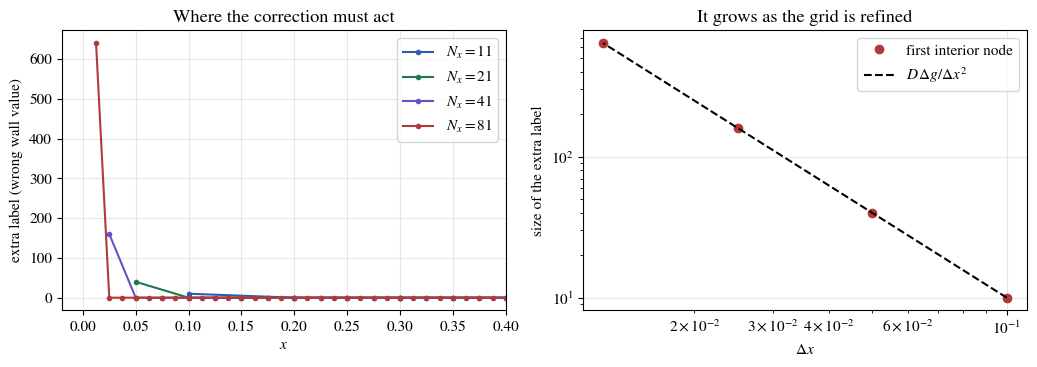

In [4]:
bc_rows = []
for n_x in [11, 21, 41, 81]:
    xb, dxb, dtb = make_grid(n_x, N_T)
    stepb, labelb = make_solver(xb, np.full(n_x - 1, D), dtb)
    T = 1 + np.sin(np.pi*xb); T[0] = WALL_TRUE; R = [T]
    for n in range(N_T):
        T = stepb(T, np.zeros(n_x - 2), gl=WALL_TRUE); R.append(T)
    R = np.array(R)
    lab_pbm = np.array([labelb(R[n], R[n + 1], gl=WALL_PBM) for n in range(N_T)])   # what the PBM step needs
    lab_ok = np.array([labelb(R[n], R[n + 1], gl=WALL_TRUE) for n in range(N_T)])   # with the right wall value
    extra = lab_pbm - lab_ok
    bc_rows.append(dict(n_x=n_x, dx=dxb, node1=float(extra[:, 0].mean()), elsewhere=float(np.abs(extra[:, 1:]).max()),
                        predicted=D*(WALL_TRUE - WALL_PBM)/dxb**2, profile=extra[N_T//2], x=xb[1:-1]))
    print(f'N={n_x:3d}: extra label at the first interior node {bc_rows[-1]["node1"]:7.1f}'
          f'   (D*dg/dx^2 = {bc_rows[-1]["predicted"]:7.1f}),  elsewhere {bc_rows[-1]["elsewhere"]:.0e}')

def plot_costa_cases_boundary():
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
    for r_, c in zip(bc_rows, ['C0', 'C2', 'C4', 'C3']):
        ax[0].plot(r_['x'], r_['profile'], 'o-', ms=3, color=c, label=f'$N_x={r_["n_x"]}$')
    ax[0].set(xlabel='$x$', ylabel='extra label (wrong wall value)', title='Where the correction must act',
              xlim=(-0.02, 0.4)); ax[0].legend()
    dxs = np.array([r_['dx'] for r_ in bc_rows]); n1 = np.array([r_['node1'] for r_ in bc_rows])
    ax[1].loglog(dxs, n1, 'o', color='C3', label='first interior node')
    ax[1].loglog(dxs, D*(WALL_TRUE - WALL_PBM)/dxs**2, '--', color=fg(), label=r'$D\,\Delta g/\Delta x^2$')
    ax[1].set(xlabel=r'$\Delta x$', ylabel='size of the extra label', title='It grows as the grid is refined')
    ax[1].legend(); plt.tight_layout()

save_dual(plot_costa_cases_boundary, 'costa_cases_boundary', FIG)
plt.show()
RESULTS['boundary'] = [{k: v for k, v in r_.items() if k not in ('profile', 'x')} for r_ in bc_rows]

On a fixed grid a correction *can* make the interior match the reference: the exact label exists. But it is a spike
at the first interior node, zero elsewhere, and its size is $D\,\Delta g/\Delta x^2$: it grows fourfold every time
the grid is halved, and the boundary value itself stays wrong. That is not a heat source anyone could identify; it
is the discrete footprint of a wrong boundary condition. **Fix wrong boundary data at the boundary.** (A wrong
*Neumann* flux enters a finite-volume scheme through the boundary cell's balance, so it looks like a source of size
$\Delta q/\Delta x$ in that cell: also grid-dependent, and also better corrected as a flux.)

## Case 2: an inaccurate parameter

Now the operator itself is wrong. The reference has a conductivity that increases across the rod,
$k(x)=k_0(1+cx)$, while the PBM uses a constant $\tilde k$. Both use the same grid and scheme, so there is no
discretization error between them. The exact label is the discrete version of

$$\sigma^*=\partial_x\big((k-\tilde k)\,\partial_x T\big),$$

which depends on **where** the node is, through $k(x)$, as well as on the temperatures. A stencil-only network
cannot represent that; adding the position $x_i$ can. (In the heat notebook position was unnecessary and time was
harmful; here the parameter error makes position part of the physics.)

case 2, stencil: CoSTA test rollout RMSE, median over seeds [0, 1, 2]: a=1.25: 1.1e-02  a=2.25: 6.2e-03  a=0.35: 7.3e-03  a=3.75: 3.5e-02


case 2, stencil + x: CoSTA test rollout RMSE, median over seeds [0, 1, 2]: a=1.25: 5.6e-03  a=2.25: 3.3e-03  a=0.35: 2.2e-03  a=3.75: 1.9e-02


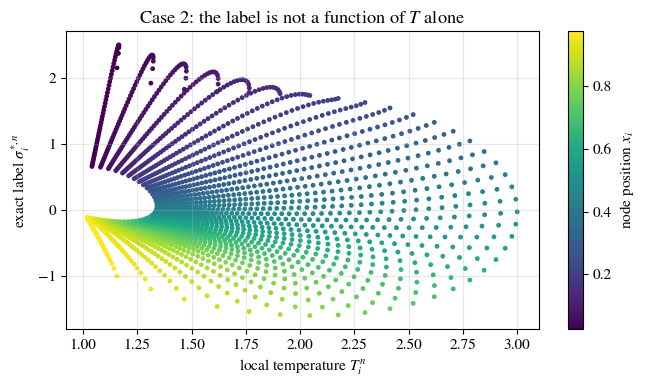

In [5]:
x2, dx2, dt2 = make_grid(N_X, N_T)
k_face_true = K_TRUE[0]*(1 + K_TRUE[1]*(x2[:-1] + x2[1:])/2)
step2_true, _ = make_solver(x2, k_face_true, dt2)
step2, label2 = make_solver(x2, np.full(N_X - 1, K_PBM), dt2)
def reference2(a):
    T = 1 + a*np.sin(np.pi*x2); out = [T]
    for n in range(N_T):
        T = step2_true(T, np.zeros(N_X - 2)); out.append(T)
    return np.array(out)
def stencil_and_x(T, n, a):
    return np.stack([T[:-2], T[1:-1], T[2:], x2[1:-1]], 1)

pbm2 = pbm_errors(step2, N_T, reference2)
case2_T, _, _ = evaluate('case 2, stencil', step2, label2, N_T, reference2, stencil)
case2_Tx, _, _ = evaluate('case 2, stencil + x', step2, label2, N_T, reference2, stencil_and_x)
RESULTS['case2'] = dict(pbm=pbm2, stencil=case2_T, stencil_plus_x=case2_Tx)

R2 = reference2(2.0)
lab2 = np.array([label2(R2[n], R2[n + 1]) for n in range(N_T)])
def plot_costa_cases_parameter():
    fig, ax = plt.subplots(figsize=(6.8, 4.0))
    sc = ax.scatter(R2[:-1, 1:-1].ravel(), lab2.ravel(), c=np.tile(x2[1:-1], N_T), s=6, cmap='viridis')
    plt.colorbar(sc, ax=ax, label='node position $x_i$')
    ax.set(xlabel='local temperature $T_i^n$', ylabel=r'exact label $\sigma^{*,n}_i$',
           title='Case 2: the label is not a function of $T$ alone')
    plt.tight_layout()

save_dual(plot_costa_cases_parameter, 'costa_cases_parameter', FIG)
plt.show()

The scatter shows why. At the same local temperature, nodes at different positions need very different
corrections, because $k-\tilde k$ changes sign along the rod. The colour (position) organizes the cloud. Adding $x_i$
to the inputs roughly halves the remaining test error. It does not remove it: the label also depends on the
*next* time level, which a level-$n$ input only approximates on this coarse time step. The correction improves
on the PBM, but a wrong parameter is often better fixed by estimating the parameter (Module 03) than by learning
its consequences.

## Case 3: discretization error only

Now the physics is exact, $\partial_t T=D\,\partial_{xx}T$, and the reference is its exact solution
$T^*=1+a\sin(\pi x)e^{-D\pi^2t}$. The PBM solves the right equation on a coarse grid ($N_x=11$) with a large time
step ($N_t=10$). The label contains nothing but the scheme's truncation error, and a correction can remove it.

The catch is that truncation error belongs to a grid. We train on the coarse grid and then deploy the frozen
correction, unchanged, on other grids and time steps.

case 3, coarse grid: CoSTA test rollout RMSE, median over seeds [0, 1, 2]: a=1.25: 4.2e-05  a=2.25: 1.1e-04  a=0.35: 1.9e-05  a=3.75: 2.2e-03
deploy on N_x= 11, N_t= 10:  PBM 5.69e-02   CoSTA (trained on 11/10) 9.52e-05
deploy on N_x= 11, N_t= 20:  PBM 3.19e-02   CoSTA (trained on 11/10) 1.85e-02
deploy on N_x= 21, N_t= 20:  PBM 3.11e-02   CoSTA (trained on 11/10) 2.27e-02
deploy on N_x= 41, N_t= 40:  PBM 1.63e-02   CoSTA (trained on 11/10) 3.50e-02


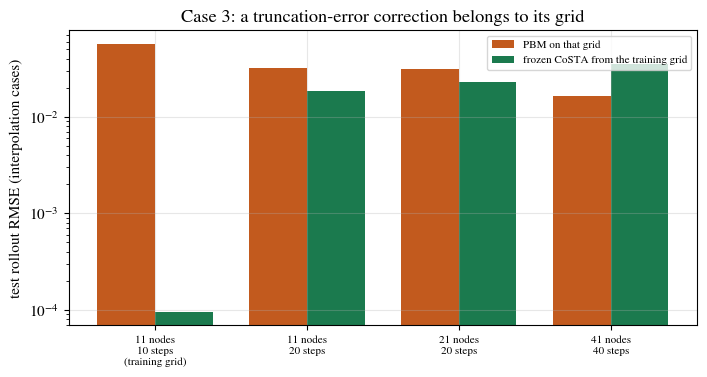

In [6]:
def coarse_setup(n_x, n_t):
    xc, _, dtc = make_grid(n_x, n_t)
    stepc, labelc = make_solver(xc, np.full(n_x - 1, D), dtc)
    ref = lambda a: np.array([1 + a*np.sin(np.pi*xc)*np.exp(-D*np.pi**2*n*dtc) for n in range(n_t + 1)])
    return stepc, labelc, ref

step3, label3, reference3 = coarse_setup(N_X_COARSE, N_T_COARSE)
pbm3 = pbm_errors(step3, N_T_COARSE, reference3)
case3, corr3, _ = evaluate('case 3, coarse grid', step3, label3, N_T_COARSE, reference3, stencil)
RESULTS['case3'] = dict(pbm=pbm3, stencil=case3)

transfer = []
for n_x, n_t in [(N_X_COARSE, N_T_COARSE), (N_X_COARSE, 2*N_T_COARSE), (2*N_X_COARSE - 1, 2*N_T_COARSE),
                 (4*N_X_COARSE - 3, 4*N_T_COARSE)]:
    stp, _, ref = coarse_setup(n_x, n_t)
    def roll(a, c=None):
        T = ref(a)[0].copy(); out = [T]
        for n in range(n_t):
            T = stp(T, np.zeros(n_x - 2) if c is None else c(stencil(T, n, a))); out.append(T)
        return np.array(out)
    e_p = np.mean([rmse(roll(a), ref(a)) for a in A_TEST[:2]])
    e_c = np.mean([rmse(roll(a, corr3), ref(a)) for a in A_TEST[:2]])
    transfer.append(dict(n_x=n_x, n_t=n_t, pbm=float(e_p), costa=float(e_c)))
    print(f'deploy on N_x={n_x:3d}, N_t={n_t:3d}:  PBM {e_p:.2e}   CoSTA (trained on {N_X_COARSE}/{N_T_COARSE}) {e_c:.2e}')
RESULTS['case3']['grid_transfer'] = transfer

def plot_costa_cases_grid():
    fig, ax = plt.subplots(figsize=(7.2, 3.9))
    lab = [f'{t["n_x"]} nodes\n{t["n_t"]} steps' + ('\n(training grid)' if i == 0 else '') for i, t in enumerate(transfer)]
    xb = np.arange(len(transfer)); w = 0.38
    ax.bar(xb - w/2, [t['pbm'] for t in transfer], w, color='C1', label='PBM on that grid')
    ax.bar(xb + w/2, [t['costa'] for t in transfer], w, color='C2', label='frozen CoSTA from the training grid')
    ax.set_yscale('log'); ax.set_xticks(xb); ax.set_xticklabels(lab, fontsize=8)
    ax.set(ylabel='test rollout RMSE (interpolation cases)', title='Case 3: a truncation-error correction belongs to its grid')
    ax.legend(fontsize=8); plt.tight_layout()

save_dual(plot_costa_cases_grid, 'costa_cases_grid', FIG)
plt.show()

On its own grid the correction removes most of the truncation error. Moved to a different time step or grid it
loses most of its benefit, and on the finest grid it makes the solution **worse** than the PBM: it keeps
compensating an error that grid no longer makes. Train and deploy with the same solver, grid and time step; a new
discretization is a new experiment.

## Case 4: modelling and discretization error together

The realistic case: the PBM misses a source **and** runs on the coarse grid. The reference is the continuous
manufactured solution

$$T^*=1+a\sin(\pi x)e^{-t}+0.4\,a\sin(2\pi x)e^{-2t},$$

two modes so that the missing source is a combination of $T-1$ and $\partial_{xx}T$ (still a function of the local
stencil). The label now contains the missing source plus the truncation error, at once.

This is also where the two prediction loops can be compared:

* **current-state** (the course notebooks): evaluate the network on $T^n$, take one corrected step;
* **predictor-based** (Blakseth et al.): take a plain PBM step to $\tilde T^{n+1}$, evaluate the network on it, re-take
  the step with the correction. Two solves per step.

Both use the same label and the same protocol. (With a single-mode reference the two would be indistinguishable:
for one eigenmode the predictor is just a scaled copy of the current state, and normalization removes the scale.)

In [7]:
x4, _, dt4 = make_grid(N_X_COARSE, N_T_COARSE)
step4, label4 = make_solver(x4, np.full(N_X_COARSE - 1, D), dt4)
def reference4(a):
    return np.array([1 + a*np.sin(np.pi*x4)*np.exp(-n*dt4) + MODE2*a*np.sin(2*np.pi*x4)*np.exp(-2*n*dt4)
                     for n in range(N_T_COARSE + 1)])
R4 = reference4(2.0)
lab4 = np.array([label4(R4[n], R4[n + 1]) for n in range(N_T_COARSE)])
# continuous missing source at the start of each step: s = dT/dt - D d2T/dx2
s4 = np.array([(-(R4[n] - 1) - MODE2*2.0*np.sin(2*np.pi*x4)*np.exp(-2*n*dt4)
                + D*np.pi**2*2.0*np.sin(np.pi*x4)*np.exp(-n*dt4)
                + D*4*np.pi**2*MODE2*2.0*np.sin(2*np.pi*x4)*np.exp(-2*n*dt4))[1:-1] for n in range(N_T_COARSE)])
print(f'label = missing source + truncation: |s| mean {np.abs(s4).mean():.2f}, |label - s| mean {np.abs(lab4 - s4).mean():.2f}')

pbm4 = pbm_errors(step4, N_T_COARSE, reference4)
case4_cur, _, _ = evaluate('case 4, current-state', step4, label4, N_T_COARSE, reference4, stencil)
case4_pred, _, _ = evaluate('case 4, predictor-based', step4, label4, N_T_COARSE, reference4, stencil,
                            variant='predictor')
RESULTS['case4'] = dict(pbm=pbm4, current_state=case4_cur, predictor=case4_pred,
                        label_parts=dict(missing_source=float(np.abs(s4).mean()),
                                         truncation=float(np.abs(lab4 - s4).mean())))

label = missing source + truncation: |s| mean 5.46, |label - s| mean 1.09


case 4, current-state: CoSTA test rollout RMSE, median over seeds [0, 1, 2]: a=1.25: 2.3e-03  a=2.25: 5.0e-03  a=0.35: 1.5e-03  a=3.75: 2.6e-02


case 4, predictor-based: CoSTA test rollout RMSE, median over seeds [0, 1, 2]: a=1.25: 2.3e-03  a=2.25: 7.3e-03  a=0.35: 1.6e-03  a=3.75: 4.4e-02


On this coarse grid the truncation part of the label is a sizeable fraction of the missing-source part, and the
correction removes both: the PBM's rollout error drops by about two orders of magnitude on the interpolation cases.
The predictor-based loop is not better here, at twice the solver cost per step. That is a finding for this problem,
not a general ranking: the predictor's input carries the PBM's own estimate of the next state, which can help when
the step is large relative to the dynamics.

## Summary across the cases

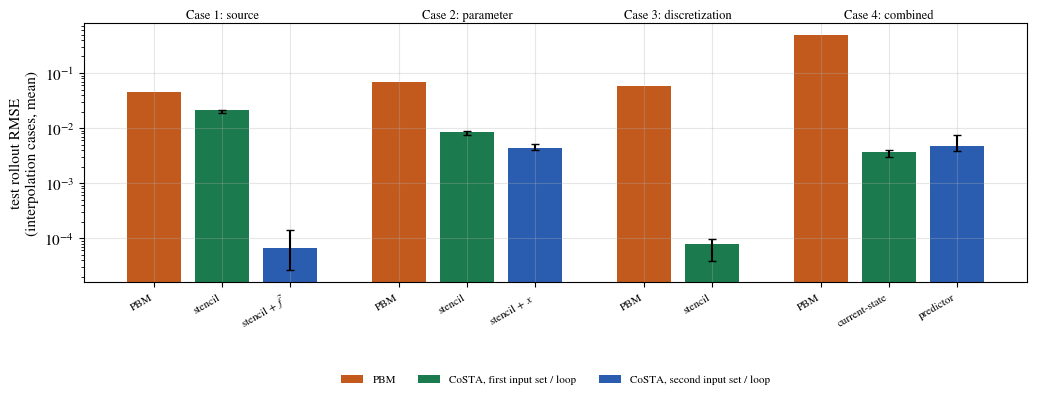

case               model                      a=1.25   a=2.25   a=0.35   a=3.75  
1: source          PBM                        6.4e-02  2.6e-02  9.0e-02  6.4e-03 
1: source          CoSTA, stencil             2.1e-02  2.1e-02  5.3e-02  4.0e-02 
1: source          CoSTA, stencil + \tilde f  6.8e-05  6.3e-05  2.3e-03  8.5e-04 
2: parameter       PBM                        4.8e-02  8.7e-02  1.3e-02  1.4e-01 
2: parameter       CoSTA, stencil             1.1e-02  6.2e-03  7.3e-03  3.5e-02 
2: parameter       CoSTA, stencil + x         5.6e-03  3.3e-03  2.2e-03  1.9e-02 
3: discretization  PBM                        4.1e-02  7.3e-02  1.1e-02  1.2e-01 
3: discretization  CoSTA, stencil             4.2e-05  1.1e-04  1.9e-05  2.2e-03 
4: combined        PBM                        3.5e-01  6.2e-01  9.7e-02  1.0e+00 
4: combined        CoSTA, current-state       2.3e-03  5.0e-03  1.5e-03  2.6e-02 
4: combined        CoSTA, predictor           2.3e-03  7.3e-03  1.6e-03  4.4e-02 
saved ../data/co

In [8]:
def med(d):
    return np.array([d[a]['median'] for a in A_TEST])
def lo(d):
    return np.array([d[a]['min'] for a in A_TEST])
def hi(d):
    return np.array([d[a]['max'] for a in A_TEST])
rows = [('1: source', 'PBM', np.array([pbm1[a] for a in A_TEST]), None),
        ('1: source', 'CoSTA, stencil', case1_T, None), ('1: source', r'CoSTA, stencil + $\tilde f$', case1_Tf, None),
        ('2: parameter', 'PBM', np.array([pbm2[a] for a in A_TEST]), None),
        ('2: parameter', 'CoSTA, stencil', case2_T, None), ('2: parameter', 'CoSTA, stencil + $x$', case2_Tx, None),
        ('3: discretization', 'PBM', np.array([pbm3[a] for a in A_TEST]), None),
        ('3: discretization', 'CoSTA, stencil', case3, None),
        ('4: combined', 'PBM', np.array([pbm4[a] for a in A_TEST]), None),
        ('4: combined', 'CoSTA, current-state', case4_cur, None), ('4: combined', 'CoSTA, predictor', case4_pred, None)]
interp = [i for i, a in enumerate(A_TEST) if min(A_TRAIN) < a < max(A_TRAIN)]

def plot_costa_cases_summary():
    fig, ax = plt.subplots(figsize=(10.5, 4.4))
    pos, labels, k, last, j = [], [], 0.0, None, 0
    shown = set()
    for case, model, vals, _ in rows:
        if case != last:
            k += 0.6; j = 0; last = case
        if isinstance(vals, dict):
            m = med(vals)[interp].mean(); l_ = lo(vals)[interp].mean(); h = hi(vals)[interp].mean()
            c, name = ('C2', 'CoSTA, first input set / loop') if j == 0 else ('C0', 'CoSTA, second input set / loop')
            ax.bar(k, m, 0.8, color=c, yerr=[[m - l_], [h - m]], capsize=3,
                   label=None if name in shown else name); shown.add(name); j += 1
        else:
            m = vals[interp].mean()
            ax.bar(k, m, 0.8, color='C1', label=None if 'PBM' in shown else 'PBM'); shown.add('PBM')
        pos.append(k); labels.append(model.replace('CoSTA, ', '')); k += 1
    ax.set_yscale('log'); ax.set_xticks(pos); ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
    for case in ['1: source', '2: parameter', '3: discretization', '4: combined']:
        idx = [p for p, r_ in zip(pos, rows) if r_[0] == case]
        ax.text(np.mean(idx), 1.02, 'Case ' + case, transform=ax.get_xaxis_transform(), ha='center', fontsize=9)
    ax.set(ylabel='test rollout RMSE\n(interpolation cases, mean)')
    ax.legend(fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.32), frameon=False)
    plt.tight_layout()

save_dual(plot_costa_cases_summary, 'costa_cases_summary', FIG)
plt.show()

print(f"{'case':18s} {'model':26s} " + ' '.join(f'a={a:<6}' for a in A_TEST))
for case, model, vals, _ in rows:
    v = med(vals) if isinstance(vals, dict) else vals
    print(f'{case:18s} {model.replace("$", ""):26s} ' + ' '.join(f'{u:.1e} ' for u in v))

with open(os.path.join(DATA, 'costa_cases_results.json'), 'w') as fh:
    json.dump(dict(config={k: globals()[k] for k in DEFAULTS}, results=RESULTS), fh, indent=1, default=str)
print('saved', os.path.relpath(os.path.join(DATA, 'costa_cases_results.json')))

**What the four cases teach.**

| Case | What the label contains | What the network needs | Where the correction can be used |
|---|---|---|---|
| 1, source | the missing part of the forcing | the PBM's forcing $\tilde f$ as an input | any trajectory whose forcing it can see |
| 1, boundary | a grid-dependent spike next to the wall | (fix the boundary instead) | only on the training grid |
| 2, parameter | the operator error, dependent on position | position (or the parameter field) | the training geometry |
| 3, discretization | the scheme's truncation error | the local stencil | the training grid and time step only |
| 4, combined | missing physics plus truncation | the local stencil | the training grid, inside the training states |

One definition of the label covers all four. Deciding the inputs and the range of validity is where the cases
differ, and that decision is part of the modelling.